<a href="https://colab.research.google.com/github/sessm216/Finphysics/blob/main/About_stochasticstuff.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Wiener, Itô and geometric brownian movement (GBM)

This notebook builds the formula used in the 'Montecarlo_v1' script:

$$S_{t+\Delta t} = S_t \exp\left[\left(\mu - \tfrac{\sigma^2}{2}\right)\Delta t + \sigma\sqrt{\Delta t}\,Z\right], \quad Z \sim N(0,1)$$

**Goals**
1. Simulating a Wiener process and numerically check its properties
2. Why are the trajectories not derivable. Why $(dW)^2 = dt$.
3. Getting to Itô's lemma and deducing the term $-\sigma^2/2$, then check it with a simulation.
4. Discretize an stochastic equation (Euler-Maruyama) and measure its error.
5. Final goal: final simulated price histograms matches lognormal function of 'Basicconcepts' notebook

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)   # generador con semilla: resultados repetibles
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Wiener process

A Wiener process called $W_t$ (standard brownian movement) is defined by 4 properties:

1. $W_0 = 0$.
2. **Independent increments:** $W_t - W_s$ is independent from the past for $t > s$.
3. **Gaussian increments:** $W_t - W_s \sim N(0,\ t-s)$.
4. **Continuous** trajectories.

We can deduce from this $\mathrm{Var}(W_t) = t$. It is a Markov process (see basic concepts notebook): the future only depends on the current value, does not depend on the past.

To simulate we divide $[0,T]$ in $\Delta t$ steps and then we add $\Delta W= \sqrt {\Delta t}\cdot Z$ increments with $Z\sim N(0,1)$.

###About the simulation:

-I am creating a $[0,T]$ array

-rng.normal: gathering samples from a Gaussian centered in 0, standard deviation $\sqrt{\Delta t}$. Produces a 5 x 1000 array (5 paths in 1000 time steps).  

-Where is the randomness!!! In the increments!

-W: ncumsum does the cummulative sum to reflect $W_t$ = all $\Delta W$ up to t.  We concatenate bc the rng-nomral produces a 1000 element array, representing 1000 t moments (because we had 1000 steps), but we need 1001 moments: we start in t=0, step=1 and end at 1000, means 1001 t elements-> we need 1001 W elements.


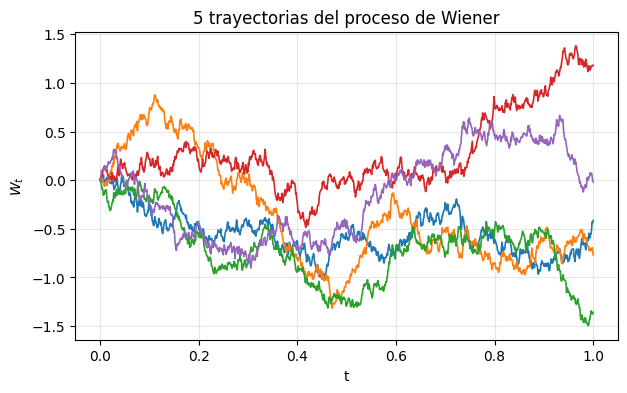

In [5]:
T = 1.0
n_steps = 1000
dt = T / n_steps
n_paths = 5

t = np.linspace(0, T, n_steps + 1)
dW = rng.normal(0.0, np.sqrt(dt), size=(n_paths, n_steps))          # incrementos
W = np.concatenate([np.zeros((n_paths, 1)), np.cumsum(dW, axis=1)], axis=1)   # W_0 = 0

plt.plot(t, W.T, lw=1.2)
plt.title("5 trayectorias del proceso de Wiener")
plt.xlabel("t")
plt.ylabel("$W_t$")
plt.show()

Sum up:


What does this all mean? A stochastic process is a group of $W_t$ variables generated randomly. The Wiener process is built as:

$$
W_0 = 0;
W_{t_k} = W_{t_{k-1}} + ΔW_k;    ΔW_k \sim N(0, Δt)
$$


### 1.1 Checking the properties by producing many trajectories

We simulate 20000 trajectories to chectk that:

* Variance is proportional t $t$
* The increments are gaussian and not correlated to each other.


Variance of W_t (theory: t)
  t = 0.25   simulated = 0.2488   theoretical = 0.2500
  t = 0.50   simulated = 0.5026   theoretical = 0.5000
  t = 1.00   simulated = 1.0038   theoretical = 1.0000

Correlation between disjoint increments: +0.0025   (theory: 0)
Skewness of W_1: +0.012   (theory: 0)
Kurtosis of W_1: 3.022    (theory: 3)


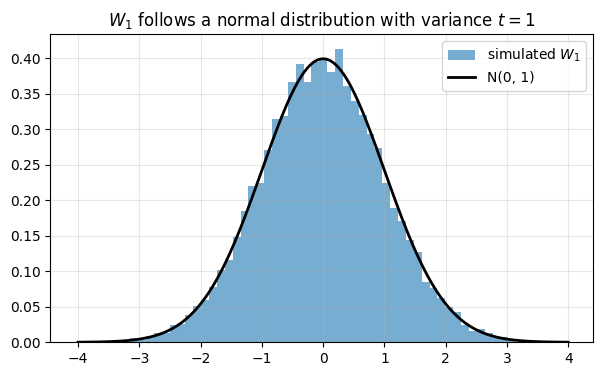

In [7]:
n_paths = 20_000
n_steps = 252
dt = T / n_steps
dW = rng.normal(0.0, np.sqrt(dt), size=(n_paths, n_steps))
W = np.concatenate([np.zeros((n_paths, 1)), np.cumsum(dW, axis=1)], axis=1)

print("Variance of W_t (theory: t)")
for tt in [0.25, 0.5, 1.0]:
    idx = int(round(tt / dt))
    print(f"  t = {tt:4.2f}   simulated = {W[:, idx].var():.4f}   theoretical = {tt:.4f}")

# Increments over non-overlapping intervals: [0.25, 0.5] and [0.5, 1.0]
i1, i2, i3 = int(0.25 / dt), int(0.5 / dt), int(1.0 / dt)
inc_a = W[:, i2] - W[:, i1]
inc_b = W[:, i3] - W[:, i2]
print(f"\nCorrelation between disjoint increments: {np.corrcoef(inc_a, inc_b)[0, 1]:+.4f}   (theory: 0)")

# Gaussianity of W_1: skewness 0 and kurtosis 3 (the normal distribution)
w1 = W[:, -1]
print(f"Skewness of W_1: {stats.skew(w1):+.3f}   (theory: 0)")
print(f"Kurtosis of W_1: {stats.kurtosis(w1, fisher=False):.3f}    (theory: 3)")

x = np.linspace(-4, 4, 400)
plt.hist(w1, bins=60, density=True, alpha=0.6, label="simulated $W_1$")
plt.plot(x, stats.norm.pdf(x), "k", lw=2, label="N(0, 1)")
plt.title("$W_1$ follows a normal distribution with variance $t = 1$")
plt.legend()
plt.show()

## 2. Continuous but not differentiable: $(dW)^2 = dt$

**Step 1: writing $\Delta W$ differently**

$$
\Delta W  = \sqrt{\Delta t} \cdot Z
$$

Where $Z ≃ N(0,1)$, an standard normal variable. By writing $\Delta W$ this way I am separating the scale (the size of the increment) $\sqrt{\Delta t}$ and the form of the increment (a Gaussian).

**Step 2: seeing what happens with the derivative**

If $W_t$ were differentiable, $\Delta W/\Delta t$ would have a finite limit as $\Delta t\to 0$. But $\Delta W \sim \sqrt{\Delta t}$, so:


$$
\frac{\Delta W}{\Delta t} = \sqrt{\Delta t} \cdot \frac{Z}{\Delta t} = \frac{Z}{\sqrt{\Delta t}}
$$

$$  \mathbb{E}\left[\frac{|\Delta W|}{\Delta t}\right] = \mathbb{E}\left[\frac{Z}{\sqrt{\Delta t}}\right]
$$
Z has always the same distribution, it has the same standard size. When $\Delta t$ changes, changes the term $\sqrt{\Delta t}$. If I wanted to differentiate I would do $\Delta t -> 0$, but this produces:


$$\mathbb{E}\left[\frac{|\Delta W|}{\Delta t}\right] = \sqrt{\frac{2}{\pi}}\,\frac{1}{\sqrt{\Delta t}} \xrightarrow{\Delta t\to 0} \infty$$

The derivative diverges.
Note: E is the expected value.

**Step 3: about the squared increments**

On the other hand, the sum of the squared increments (quadratic variation) **does converge**, and not to zero:

$$\sum_i (\Delta W_i)^2 \xrightarrow{\Delta t\to 0} T$$

This is the reason for the rule $(dW)^2 = dt$, which in ordinary calculus would be $(dx)^2 \approx 0$.

This will be important for Ito's lemma!!!

In [9]:
print(f"{'steps':>8} {'Expected valueE|dW|/dt (sim)':>16} {'Theory':>10} {'Sum dW^2 (average)':>20} {'std':>8}")
for n in [10, 100, 1_000, 10_000]:
    dt_n = T / n
    dW_n = rng.normal(0.0, np.sqrt(dt_n), size=(2_000, n))
    deriv = np.mean(np.abs(dW_n) / dt_n)
    teoria = np.sqrt(2 / np.pi) / np.sqrt(dt_n)
    qv = (dW_n ** 2).sum(axis=1)             # variación cuadrática de cada trayectoria
    print(f"{n:8d} {deriv:16.2f} {teoria:10.2f} {qv.mean():20.4f} {qv.std():8.4f}")

   steps Expected valueE|dW|/dt (sim)     Theory   Sum dW^2 (average)      std
      10             2.53       2.52               1.0081   0.4569
     100             7.96       7.98               0.9974   0.1393
    1000            25.25      25.23               1.0012   0.0453
   10000            79.79      79.79               1.0002   0.0143




**Step 4: what does this script do?**

We are checking these results with a simulation.
We are doing $T$ goes from 0.1 to 0.0001, which is equivalent to $\Delta t ->0$.

We calculate the term $|\Delta W|/\Delta t $ for each increment and then we average over all the array, so that we estimate the expected value $E$. Then we compare it with the exact value $\sqrt{\Delta 2/\pi}\sqrt{\Delta t}$. Finally we calculate the squared variation and its dispersion. We print everything.

* Column 2 and 3 (Expected value numerical and theoretical) show that the  'derivative' diverges and they escalate with $\sqrt n$.
* Column 4 shows the average  of $ΣdW²$ which stays around 1. It is stable.
* Column 5 shows that the standard deviations decreases as we increase n, meaning the smaller the step, the more deterministic the standard deviation is, until it approaches the T value in the limit.

Remember: T is the duration of the time interval being simulated. We set T=1.0. The steps are $dt=T/n$.

**About the std:**

It is computed as:

$$
std = √(2T²/n) = T · √(2/n)
$$

When n grows, the std deviation goes to 0. This means the sum of squares stops changing from one trajectory to another, and they all yield the same number T. Something that initially depended on randomness becomes a fixed value. For this reason we shall treat (dW)² as dt.

Final comment: you can change T to 5 and all square sums should yield 5. The std deviation would be $5\sqrt{2/n}$.

## 3. La ecuación diferencial estocástica del GBM

El modelo de precios es:

$$dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$$

- $\mu S_t\,dt$: **deriva** (tendencia determinista). Es el $A_1$ de tu Fokker-Planck.
- $\sigma S_t\,dW_t$: **ruido proporcional al precio**. Su cuadrado, $\tfrac12\sigma^2 S^2$, es el coeficiente de difusión $A_2$.

Por qué proporcional al precio: lo que fluctúa de forma estable es el **retorno** $dS/S$, no el precio absoluto. Eso conecta con tus log-retornos: $\ln(S_{t+\Delta t}/S_t)$.

La densidad de probabilidad de $S_t$ obedece la ecuación de Fokker-Planck de tus apuntes con esos coeficientes, y su solución es la lognormal.

## 4. Lema de Itô: de dónde sale $-\sigma^2/2$

Para una función $f(S)$ el cálculo ordinario daría $df = f'\,dS$. Con ruido hay que conservar el término de segundo orden:

$$df = f'(S)\,dS + \tfrac12 f''(S)\,(dS)^2$$

con las reglas $(dW)^2 = dt$, $dt\,dW = 0$, $(dt)^2 = 0$, de modo que $(dS)^2 = \sigma^2 S^2\,dt$.

Tomamos $f(S) = \ln S$, con $f' = 1/S$ y $f'' = -1/S^2$:

$$d\ln S = \frac{1}{S}\left(\mu S\,dt + \sigma S\,dW\right) - \frac{1}{2S^2}\,\sigma^2 S^2\,dt = \left(\mu - \tfrac{\sigma^2}{2}\right)dt + \sigma\,dW$$

Integrando entre $0$ y $T$:

$$S_T = S_0 \exp\left[\left(\mu - \tfrac{\sigma^2}{2}\right)T + \sigma W_T\right]$$

Como $W_T \sim N(0,T)$, el logaritmo $\ln S_T$ es normal con media $\ln S_0 + (\mu - \sigma^2/2)T$ y desviación $\sigma\sqrt{T}$. Es decir, $S_T$ es **lognormal** con los parámetros de tu sección 1.1:

$$\mu_{\log} = \ln S_0 + \left(\mu - \tfrac{\sigma^2}{2}\right)T, \qquad \sigma_{\log} = \sigma\sqrt{T}$$

### 4.1 Comprobación numérica

Simulamos $S_T$ **directamente desde la ecuación diferencial** (Euler-Maruyama, sin usar la fórmula exacta) y miramos $\mathbb{E}[\ln S_T]$. El cálculo ordinario predeciría $\ln S_0 + \mu T$; Itô predice $\ln S_0 + (\mu - \sigma^2/2)T$.

In [ ]:
S0, mu, sigma, T = 100.0, 0.10, 0.30, 1.0
N = 200_000
n_steps = 252
dt = T / n_steps

S = np.full(N, S0)
for _ in range(n_steps):
    Z = rng.standard_normal(N)
    S = S + mu * S * dt + sigma * S * np.sqrt(dt) * Z      # Euler-Maruyama sobre dS

mean_ln = np.log(S).mean()
se = np.log(S).std() / np.sqrt(N)                           # error estándar de la media

print(f"E[ln S_T] simulada            : {mean_ln:.4f}  (± {2*se:.4f})")
print(f"Itô      ln S0 + (mu - s²/2)T : {np.log(S0) + (mu - sigma**2/2) * T:.4f}")
print(f"Ordinario ln S0 + mu T        : {np.log(S0) + mu * T:.4f}")
print()
print(f"E[S_T] simulada               : {S.mean():.2f}")
print(f"Teoría  S0 exp(mu T)          : {S0 * np.exp(mu * T):.2f}")

**Lectura:** el logaritmo del precio crece más despacio que $\mu T$: la volatilidad "come" $\sigma^2/2$ de crecimiento logarítmico. Sin embargo, el **precio medio** sí crece a tasa $\mu$. Ambos hechos son compatibles porque la lognormal tiene la media por encima de la mediana (esto explica que en nuestro script anterior la media saliera mayor que la mediana).

## 5. Euler-Maruyama y su error

Discretizar una ecuación estocástica con el esquema de Euler-Maruyama:

$$S_{k+1} = S_k + \mu S_k\,\Delta t + \sigma S_k\,\Delta W_k, \qquad \Delta W_k = \sqrt{\Delta t}\,Z_k$$

Como el GBM tiene solución exacta, podemos medir el error. Usamos **el mismo camino browniano** para la solución exacta y para Euler con distintos números de pasos, y medimos el error fuerte $\mathbb{E}|S_T^{\text{Euler}} - S_T^{\text{exacto}}|$.

In [ ]:
S0, mu, sigma, T = 100.0, 0.10, 0.30, 1.0
N = 5_000
n_fine = 1024

dW_fine = rng.normal(0.0, np.sqrt(T / n_fine), size=(N, n_fine))
W_T = dW_fine.sum(axis=1)
S_exact = S0 * np.exp((mu - 0.5 * sigma**2) * T + sigma * W_T)

pasos = [4, 16, 64, 256, 1024]
errores = []
for n in pasos:
    dt_n = T / n
    # agrupamos los incrementos finos para obtener el MISMO camino con menos pasos
    dW_n = dW_fine.reshape(N, n, n_fine // n).sum(axis=2)
    S = np.full(N, S0)
    for k in range(n):
        S = S + mu * S * dt_n + sigma * S * dW_n[:, k]
    errores.append(np.mean(np.abs(S - S_exact)))

for n, e in zip(pasos, errores):
    print(f"pasos = {n:5d}   dt = {T/n:.5f}   error fuerte = {e:.4f}")

plt.loglog(pasos, errores, "o-", label="error de Euler-Maruyama")
ref = errores[0] * (np.array(pasos) / pasos[0]) ** -0.5
plt.loglog(pasos, ref, "k--", label="pendiente −1/2")
plt.xlabel("número de pasos")
plt.ylabel("error fuerte")
plt.title("El error de Euler-Maruyama cae como $\\sqrt{\\Delta t}$")
plt.legend()
plt.show()

**Lectura:** el error baja como $\sqrt{\Delta t}$ (orden fuerte 1/2): para reducirlo a la mitad hacen falta **cuatro** veces más pasos. Por eso el script usa la forma exponencial exacta (la del recuadro inicial): no tiene error de discretización para el GBM.

## 6. Hito: histograma del precio final frente a la lognormal

Simulamos un único activo paso a paso (forma exponencial, 252 pasos al año) y comparamos el histograma de $S_T$ con la densidad lognormal teórica, construida con los parámetros de tu notebook:

- `s` = $\sigma_{\log} = \sigma\sqrt{T}$
- `scale` = $e^{\mu_{\log}} = S_0\,e^{(\mu - \sigma^2/2)T}$

In [ ]:
S0, mu, sigma, T = 100.0, 0.10, 0.30, 5.0      # horizonte de 5 años
N = 100_000
dias = 252
n_steps = int(T * dias)
dt = T / n_steps

S = np.full(N, S0)
for _ in range(n_steps):
    Z = rng.standard_normal(N)
    S = S * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z)

# Lognormal teórica (misma parametrización que usabas con scipy)
s_log = sigma * np.sqrt(T)
scale = S0 * np.exp((mu - 0.5 * sigma**2) * T)
dist = stats.lognorm(s=s_log, scale=scale)

x = np.linspace(1, np.percentile(S, 99.5), 600)
plt.hist(S, bins=120, range=(0, x[-1]), density=True, alpha=0.6, label="$S_T$ simulado")
plt.plot(x, dist.pdf(x), "k", lw=2, label="lognormal teórica")
plt.axvline(scale, color="gray", ls="--", label=f"mediana = {scale:.1f}")
plt.axvline(S0 * np.exp(mu * T), color="red", ls=":", label=f"media = {S0*np.exp(mu*T):.1f}")
plt.title(f"Precio a {T:.0f} años: simulación frente a lognormal")
plt.xlabel("$S_T$")
plt.ylabel("densidad")
plt.legend()
plt.show()

In [ ]:
# Comparación cuantitativa
teoria = {
    "media":   S0 * np.exp(mu * T),
    "mediana": scale,
    "desv. típica": dist.std(),
    "percentil 5": dist.ppf(0.05),
    "percentil 95": dist.ppf(0.95),
}
sim = {
    "media":   S.mean(),
    "mediana": np.median(S),
    "desv. típica": S.std(),
    "percentil 5": np.percentile(S, 5),
    "percentil 95": np.percentile(S, 95),
}
print(f"{'estadístico':>14} {'simulado':>10} {'teórico':>10} {'error rel.':>11}")
for k in teoria:
    err = abs(sim[k] - teoria[k]) / teoria[k] * 100
    print(f"{k:>14} {sim[k]:10.2f} {teoria[k]:10.2f} {err:10.2f}%")

# Test de normalidad sobre ln(S_T) con los parámetros teóricos
ks = stats.kstest(np.log(S), stats.norm(loc=np.log(scale), scale=s_log).cdf)
print(f"\nTest KS de ln(S_T) frente a N(mu_log, sigma_log): p-valor = {ks.pvalue:.3f}")
print("(un p-valor grande indica que no hay evidencia contra la lognormal)")

ok = all(abs(sim[k] - teoria[k]) / teoria[k] < 0.02 for k in ["media", "mediana", "percentil 5", "percentil 95"])
print("\nHITO CUMPLIDO" if ok else "\nRevisa: algún estadístico se desvía más del 2%")

## 7. Ejercicios

1. **Sensibilidad a $\sigma$.** Repite el hito con $\sigma = 0.1$ y $\sigma = 0.6$. ¿Cómo cambian la distancia entre media y mediana y la asimetría? Relaciónalo con tu figura de la sección 1.1 de `Basicconcepts.ipynb`.
2. **Mediana igual al precio inicial.** ¿Qué valor de $\mu$ (en función de $\sigma$) hace que la mediana de $S_T$ coincida con $S_0$? Compruébalo con la simulación.
3. **Itô con otra función.** Aplica el lema de Itô a $f(S) = S^2$ y obtén $d(S^2)$. Verifica numéricamente $\mathbb{E}[S_T^2] = S_0^2\,e^{(2\mu + \sigma^2)T}$.
4. **Sin la corrección.** Simula usando $\exp[\mu\,\Delta t + \sigma\sqrt{\Delta t}\,Z]$ (sin $-\sigma^2/2$). ¿Qué ocurre con la media de $S_T$ frente a $S_0 e^{\mu T}$?
5. **Dos activos.** Genera dos Wiener correlacionados con $\rho = 0.5$ usando $W^{(2)} = \rho W^{(1)} + \sqrt{1-\rho^2}\,\tilde W$ y comprueba la correlación empírica. Es el paso previo a Cholesky (Fase 5).

## 8. Lista de comprobación de la Fase 2

- [ ] Puedo enunciar las cuatro propiedades del proceso de Wiener.
- [ ] Entiendo por qué $(dW)^2 = dt$ y por qué las trayectorias no son derivables.
- [ ] Sé deducir $d\ln S$ con el lema de Itô y de dónde sale el $-\sigma^2/2$.
- [ ] Sé relacionar los parámetros $\mu_{\log}$ y $\sigma_{\log}$ de la lognormal con $\mu$, $\sigma$ y $T$ del GBM.
- [ ] El hito (sección 6) se ejecuta y dice **HITO CUMPLIDO**.
- [ ] He resuelto al menos los ejercicios 1 a 3.

**Siguiente:** Fase 3 (series temporales y datos reales, cap. 5 y 8 de Schmidt).